# figures — bảng và biểu đồ từ log huấn luyện (TN, issue #26)

Đọc toàn bộ `logs/<model>_L<L>_s<seed>.csv`, `logs/*_summary.json` và `logs/bench/*.csv` rồi sinh:

| # | Nội dung | Phục vụ | File ra (`figures/`) |
|---|---|---|---|
| Bảng 1 | Kiểm tra sức khỏe từng lượt (mục D tài liệu hướng dẫn) + số liệu điền Sheet | TN review PR log | `runs_summary.csv`, `runs_summary.md` |
| Hình 1 | Đường val BPC theo bước, mỗi L một khung, Mamba vs Transformer (nhiều seed: trung bình + dải min–max) | RQ1 sơ bộ, kiểm tra hội tụ (Q10) | `fig1_val_bpc_by_L.png` |
| Hình 2 | Val BPC tốt nhất theo L | RQ1 sơ bộ | `fig2_best_val_bpc_vs_L.png` |
| Hình 3 | Tốc độ huấn luyện và bộ nhớ đỉnh theo L (bench.py, T4) | RQ2 | `fig3_train_speed_mem_vs_L.png` |
| Bảng 2 | Tốc độ bench + thời gian huấn luyện thực tế theo L | RQ2 | `rq2_table.md` |
| Bảng 3 | BPC toàn bộ test, Top-1/Top-3 (mode a, b, gộp) và KSR từ `logs/<run>_eval.json`, so ghép cặp Mamba vs Transformer (t ghép cặp, McNemar) | RQ1 | `rq1_suggest_table.md` |

**Cách chạy:** mở từ thư mục gốc repo (hoặc `notebooks/`), Run All. Trên Kaggle: clone repo như cell 2 của `train_run.ipynb` rồi chạy notebook này (không cần GPU). Có log mới merge vào `logs/` thì chạy lại là hình tự cập nhật.

Lưu ý khi đọc: `val_bpc` lúc huấn luyện chỉ đo trên 20 batch val cố định, để theo dõi. Con số so sánh cuối cùng trong báo cáo là BPC trên toàn bộ test (`docs/eval_spec.md` mục 1) ở Bảng 3.

In [1]:
import json, math, re
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "train.py").exists() and (p / "logs").is_dir())
LOGS, OUT = ROOT / "logs", ROOT / "figures"
OUT.mkdir(exist_ok=True)

RUN_RE = re.compile(r"^(mamba|transformer)_L(\d+)_s(\d+)$")      # bỏ try_*, compare_*, _smoke
MODELS = ["mamba", "transformer"]
LABEL = {"mamba": "Mamba", "transformer": "Transformer"}
COLOR = {"mamba": "#257de0", "transformer": "#f47230"}             # cố định theo model ở mọi hình
LS = [256, 1024, 4096]
FULL_STEPS = 6103                                                  # 200M ký tự / 32.768 ký tự mỗi bước (Q6, Q10)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#999999", "axes.labelcolor": "#333333", "xtick.color": "#555555", "ytick.color": "#555555",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "lines.linewidth": 2,
    "legend.frameon": False,
})

def vn(x, nd=0):
    """Số kiểu Việt Nam: 67.918 · 1,7151"""
    s = f"{x:,.{nd}f}"
    return s.replace(",", "_").replace(".", ",").replace("_", ".")

COMMA = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))        # trục y kiểu 1,7 thay cho 1.7

def end_labels(ax, items, min_gap):
    # Ghi giá trị cuối đường, đẩy hai nhãn gần nhau ra xa để không chồng
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y, _ in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + min_gap)
    for (x, _, txt), y in zip(items, ys):
        ax.annotate(txt, (x, y), xytext=(5, 0), textcoords="offset points", va="center", fontsize=9, color="#333333",
                    annotation_clip=False)

print("Repo:", ROOT)

Repo: /home/claude/mamba-vi-keyboard


## Bảng 1 — Các lượt đã có log và kiểm tra sức khỏe

In [2]:
# --- bench: trung vị theo (model, L) ở batch chuẩn 32.768 ký tự/bước; bỏ các file quét theo B ---
bench_frames = []
for f in sorted((LOGS / "bench").glob("bench_*.csv")):
    b = pd.read_csv(f)
    if b.groupby(["model", "seq_len"]).batch_size.nunique().max() > 1:   # file quét B ở cùng L
        continue
    bench_frames.append(b.assign(file=f.stem))
bench = pd.concat(bench_frames, ignore_index=True)
bench = bench[(bench.status == "ok") & (bench.chars_per_step == 32768)]
bench_med = (bench.groupby(["model", "seq_len"])
             .agg(chars_per_sec=("chars_per_sec", "median"), cps_min=("chars_per_sec", "min"),
                  cps_max=("chars_per_sec", "max"), peak_mem_mb=("peak_mem_mb", "median"), n=("file", "nunique"))
             .reset_index())

# --- lượt huấn luyện ---
rows, curves = [], {}
for csv in sorted(LOGS.glob("*.csv")):
    m = RUN_RE.match(csv.stem)
    if not m:
        continue
    model, L, seed = m.group(1), int(m.group(2)), int(m.group(3))
    log = pd.read_csv(csv)
    val = log.dropna(subset=["val_bpc"])
    curves[csv.stem] = val[["step", "val_bpc"]]
    summ_path = LOGS / f"{csv.stem}_summary.json"
    s = json.loads(summ_path.read_text(encoding="utf-8")) if summ_path.exists() else {}
    tail = val[val.step >= val.step.max() - 1103]                    # ≈ 1.000 bước cuối: lượt đủ 6.103 bước -> từ bước 5000 (như Q10)
    end = log.step.max() - 203                                       # ≈ 200 bước cuối, như Q10
    train_bits = log[(log.step >= end)].train_loss.mean() / math.log(2)
    val_end = val[val.step >= end].val_bpc.mean()
    tps = s.get("mean_tokens_per_sec", log.tokens_per_sec.median())
    ref = bench_med.query("model == @model and seq_len == @L").chars_per_sec
    ref = float(ref.iloc[0]) if len(ref) else float("nan")
    steps = int(s.get("steps", log.step.max()))
    rows.append({
        "run": csv.stem, "model": model, "L": L, "seed": seed, "steps": steps,
        "best_val_bpc": s.get("best_val_bpc", val.val_bpc.min()), "last_val_bpc": val.val_bpc.iloc[-1],
        "drop_last_1k": tail.val_bpc.iloc[0] - tail.val_bpc.iloc[-1],
        "gap_val_train": val_end - train_bits,
        "chars_per_sec": tps, "bench_cps": ref, "vs_bench_pct": 100 * (tps / ref - 1),
        "peak_mem_mb": s.get("peak_mem_mb", log.peak_mem_mb.max()),
        "gpu_hours": s.get("train_time_s", float("nan")) / 3600,
        "gpu": s.get("gpu_name", log.gpu_name.iloc[-1]), "resumed_from": s.get("resumed_from_step"),
    })

runs = pd.DataFrame(rows).sort_values(["L", "model", "seed"]).reset_index(drop=True)
runs["ok_steps"] = runs.steps == FULL_STEPS
runs["ok_gpu"] = runs.gpu.eq("Tesla T4")
runs["ok_speed"] = runs.vs_bench_pct.abs() <= 20
runs["ok_nan"] = [curves[r].val_bpc.notna().all() for r in runs.run]
runs["OK"] = runs[["ok_steps", "ok_gpu", "ok_speed", "ok_nan"]].all(axis=1)

runs.to_csv(OUT / "runs_summary.csv", index=False)
show = runs.assign(
    best_val_bpc=runs.best_val_bpc.map(lambda x: vn(x, 4)), drop_last_1k=runs.drop_last_1k.map(lambda x: vn(x, 4)),
    gap_val_train=runs.gap_val_train.map(lambda x: vn(x, 2)), chars_per_sec=runs.chars_per_sec.map(vn),
    vs_bench_pct=runs.vs_bench_pct.map(lambda x: f"{x:+.1f}%".replace(".", ",")),
    peak_mem_mb=runs.peak_mem_mb.map(vn), gpu_hours=runs.gpu_hours.map(lambda x: vn(x, 2)),
    OK=runs.OK.map({True: "đạt", False: "XEM LẠI"}),
)[["run", "steps", "best_val_bpc", "drop_last_1k", "gap_val_train", "chars_per_sec", "vs_bench_pct",
   "peak_mem_mb", "gpu_hours", "gpu", "OK"]]
show.columns = ["Lượt", "Bước", "Val BPC tốt nhất", "Giảm 1.000 bước cuối", "Val − train (bit)",
                "Ký tự/s", "So với bench", "Bộ nhớ đỉnh (MB)", "Giờ GPU", "GPU", "Kiểm tra"]
(OUT / "runs_summary.md").write_text(show.to_markdown(index=False, disable_numparse=True), encoding="utf-8")
display(Markdown(show.to_markdown(index=False, disable_numparse=True)))

bad = runs[~runs.OK]
for _, r in bad.iterrows():
    why = [n for n, ok in [("steps ≠ 6103", r.ok_steps), ("không phải T4", r.ok_gpu),
                           ("tốc độ lệch bench > 20%", r.ok_speed), ("có NaN", r.ok_nan)] if not ok]
    print(f"XEM LẠI {r.run}: " + ", ".join(why))
missing = [f"{m}_L{L}_s{s}" for m in MODELS for L, seeds in [(256, [0]), (1024, [0, 1, 2]), (4096, [0])]
           for s in seeds if f"{m}_L{L}_s{s}" not in set(runs.run)]
print(f"Đã có {len(runs)}/10 lượt. Còn thiếu: {', '.join(missing) if missing else 'không'}")

| Lượt                | Bước   | Val BPC tốt nhất   | Giảm 1.000 bước cuối   | Val − train (bit)   | Ký tự/s   | So với bench   | Bộ nhớ đỉnh (MB)   | Giờ GPU   | GPU      | Kiểm tra   |
|:--------------------|:-------|:-------------------|:-----------------------|:--------------------|:----------|:---------------|:-------------------|:----------|:---------|:-----------|
| mamba_L256_s0       | 6103   | 1,7151             | 0,0084                 | 0,24                | 67.918    | +3,5%          | 2.740              | 0,83      | Tesla T4 | đạt        |
| transformer_L256_s0 | 6103   | 1,6863             | 0,0194                 | 0,16                | 132.129   | -4,6%          | 2.728              | 0,43      | Tesla T4 | đạt        |

Đã có 2/10 lượt. Còn thiếu: mamba_L1024_s0, mamba_L1024_s1, mamba_L1024_s2, mamba_L4096_s0, transformer_L1024_s0, transformer_L1024_s1, transformer_L1024_s2, transformer_L4096_s0


## Hình 1 — Val BPC theo bước, mỗi L một khung

Cùng trục y để so được giữa các L. L = 1.024 có 3 seed: đường là trung bình, dải mờ là min–max giữa các seed.

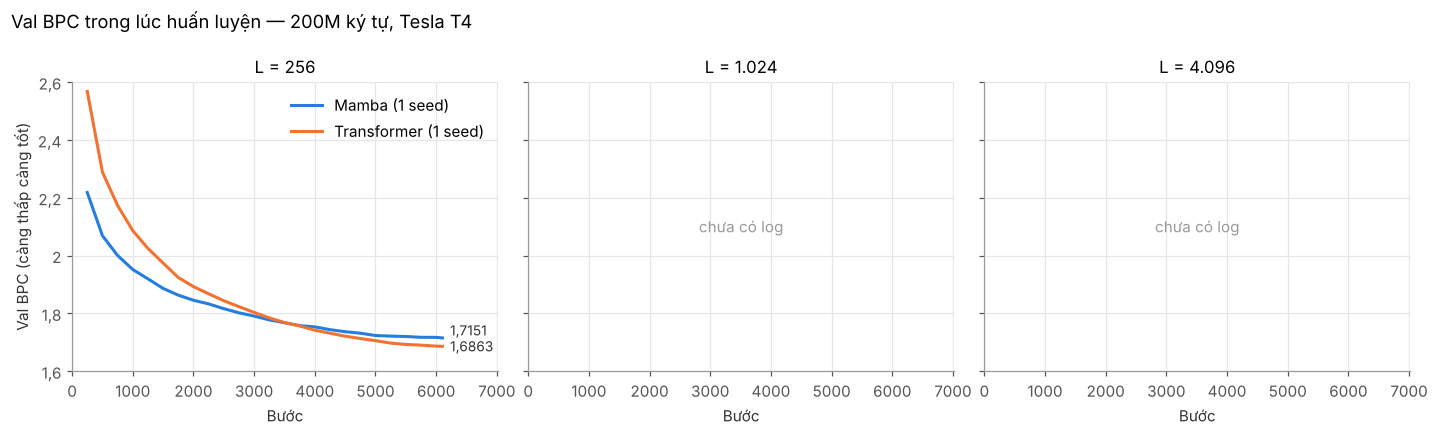

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, L in zip(axes, LS):
    has, ends = False, []
    for model in MODELS:
        names = [r for r in curves if RUN_RE.match(r) and RUN_RE.match(r).group(1) == model and int(RUN_RE.match(r).group(2)) == L]
        if not names:
            continue
        has = True
        wide = pd.concat([curves[n].set_index("step").val_bpc.rename(n) for n in names], axis=1).sort_index()
        mean = wide.mean(axis=1)
        ax.plot(mean.index, mean.values, color=COLOR[model], label=f"{LABEL[model]} ({len(names)} seed)")
        if len(names) > 1:
            ax.fill_between(wide.index, wide.min(axis=1), wide.max(axis=1), color=COLOR[model], alpha=0.18, linewidth=0)
        ends.append((mean.index[-1], mean.iloc[-1], vn(mean.iloc[-1], 4)))
    ax.set_title(f"L = {vn(L)}")
    ax.set_xlabel("Bước")
    if not has:
        ax.text(0.5, 0.5, "chưa có log", transform=ax.transAxes, ha="center", va="center", color="#999999")
    else:
        ax.legend(loc="upper right")
        end_labels(ax, ends, min_gap=0.055)
    ax.set_xlim(0, FULL_STEPS * 1.15)
axes[0].set_ylabel("Val BPC (càng thấp càng tốt)")
axes[0].set_ylim(1.6, 2.6)
axes[0].yaxis.set_major_formatter(COMMA)
fig.suptitle("Val BPC trong lúc huấn luyện — 200M ký tự, Tesla T4", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(OUT / "fig1_val_bpc_by_L.png", bbox_inches="tight")
plt.show()

## Hình 2 — Val BPC tốt nhất theo L

Điểm là trung bình các seed, vạch dọc là min–max (chỉ có ở L = 1.024). Mới là `val_bpc` trên 20 batch — sơ bộ cho RQ1, chưa phải BPC test.

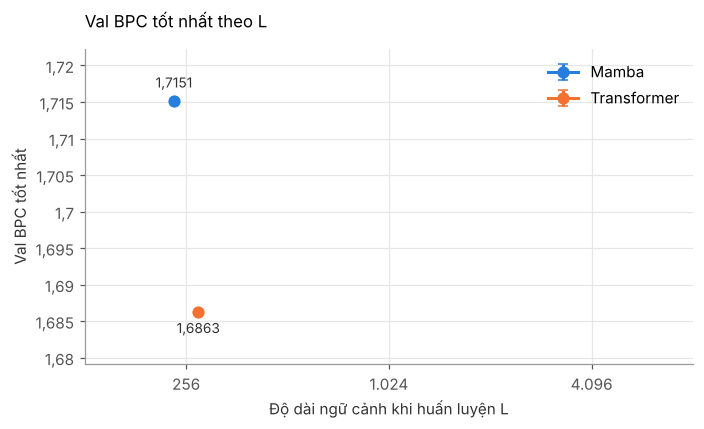

In [4]:
agg = (runs.groupby(["model", "L"]).best_val_bpc.agg(["mean", "min", "max", "count"]).reset_index())
fig, ax = plt.subplots(figsize=(6.5, 4))
xpos = {L: i for i, L in enumerate(LS)}
for k, model in enumerate(MODELS):
    d = agg[agg.model == model]
    if d.empty:
        continue
    x = [xpos[L] + (k - 0.5) * 0.12 for L in d.L]
    ax.errorbar(x, d["mean"], yerr=[d["mean"] - d["min"], d["max"] - d["mean"]], fmt="o-", color=COLOR[model],
                markersize=7, capsize=3, label=LABEL[model])
    for xi, (_, r) in zip(x, d.iterrows()):
        ax.annotate(vn(r["mean"], 4) + (f"  (n={int(r['count'])})" if r["count"] > 1 else ""), (xi, r["mean"]),
                    xytext=(0, 9 if model == "mamba" else -14), textcoords="offset points", ha="center",
                    fontsize=9, color="#333333")
ax.set_xticks(range(len(LS)), [vn(L) for L in LS])
ax.set_xlim(-0.5, len(LS) - 0.5)
ax.set_xlabel("Độ dài ngữ cảnh khi huấn luyện L")
ax.set_ylabel("Val BPC tốt nhất")
ax.set_title("Val BPC tốt nhất theo L", loc="left", pad=14)
ax.margins(y=0.25)
ax.yaxis.set_major_formatter(COMMA)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "fig2_best_val_bpc_vs_L.png", bbox_inches="tight")
plt.show()

## Hình 3 — RQ2: tốc độ huấn luyện và bộ nhớ đỉnh theo L

Từ `bench.py` (tuần 1, T4, fp16, 32.768 ký tự/bước, token ngẫu nhiên): điểm là trung vị các lần chạy, vạch dọc là min–max. L = 8.192 và 16.384 là phần khám phá vượt thiết kế. Hai đại lượng khác đơn vị nên vẽ hai khung riêng.

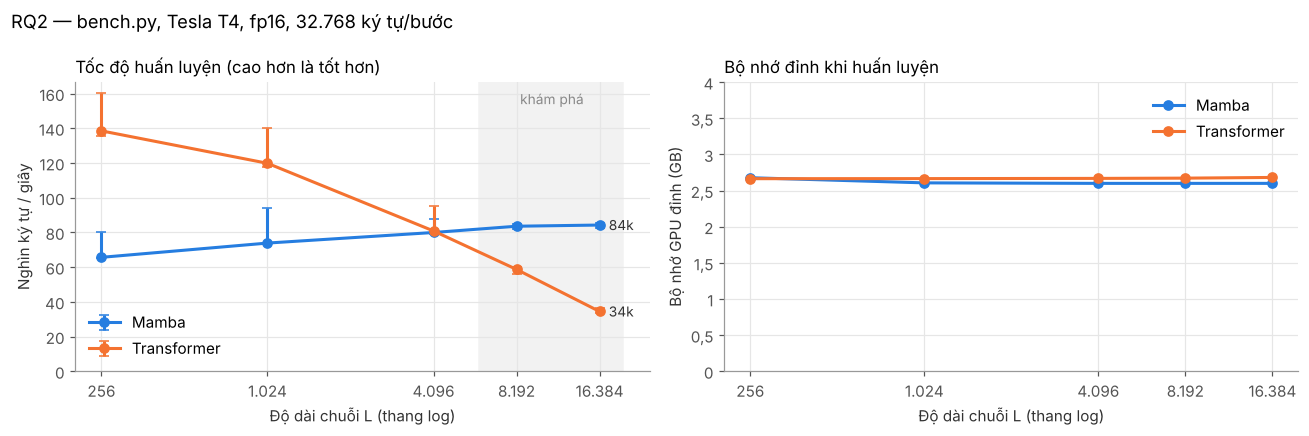

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for model in MODELS:
    d = bench_med[bench_med.model == model].sort_values("seq_len")
    a1.errorbar(d.seq_len, d.chars_per_sec / 1000, yerr=[(d.chars_per_sec - d.cps_min) / 1000, (d.cps_max - d.chars_per_sec) / 1000],
                fmt="o-", color=COLOR[model], markersize=6, capsize=3, label=LABEL[model])
    a2.plot(d.seq_len, d.peak_mem_mb / 1024, "o-", color=COLOR[model], markersize=6, label=LABEL[model])
    last = d.iloc[-1]
    a1.annotate(f"{vn(last.chars_per_sec / 1000)}k", (last.seq_len, last.chars_per_sec / 1000), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#333333")
for a in (a1, a2):
    a.set_xscale("log", base=2)
    ticks = sorted(bench_med.seq_len.unique())
    a.set_xticks(ticks, [vn(t) for t in ticks])
    a.minorticks_off()
    a.set_xlabel("Độ dài chuỗi L (thang log)")
    a.legend()
a1.axvspan(6000, 20000, color="#f2f2f2", zorder=0)
a1.text(11000, a1.get_ylim()[1] * 0.97, "khám phá", ha="center", va="top", fontsize=9, color="#888888")
a1.set_ylabel("Nghìn ký tự / giây")
a1.set_ylim(bottom=0)
a1.set_title("Tốc độ huấn luyện (cao hơn là tốt hơn)", loc="left")
a2.set_ylabel("Bộ nhớ GPU đỉnh (GB)")
a2.set_ylim(0, 4)
a2.yaxis.set_major_formatter(COMMA)
a2.set_title("Bộ nhớ đỉnh khi huấn luyện", loc="left")
fig.suptitle("RQ2 — bench.py, Tesla T4, fp16, 32.768 ký tự/bước", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(OUT / "fig3_train_speed_mem_vs_L.png", bbox_inches="tight")
plt.show()

## Bảng 2 — RQ2: tốc độ bench và thời gian huấn luyện thực tế theo L

In [6]:
wide = bench_med.pivot(index="seq_len", columns="model", values=["chars_per_sec", "peak_mem_mb"])
t = pd.DataFrame({
    "L": [vn(L) for L in wide.index],
    "Transformer ký tự/s": wide[("chars_per_sec", "transformer")].map(vn).values,
    "Mamba ký tự/s": wide[("chars_per_sec", "mamba")].map(vn).values,
    "Mamba / Transformer": (wide[("chars_per_sec", "mamba")] / wide[("chars_per_sec", "transformer")]).map(lambda x: vn(x, 2)).values,
    "Bộ nhớ T / M (MB)": [f"{vn(a)} / {vn(b)}" for a, b in zip(wide[("peak_mem_mb", "transformer")], wide[("peak_mem_mb", "mamba")])],
})
hours = runs.groupby(["L", "model"]).gpu_hours.mean().unstack()
t["Giờ GPU thực tế T / M"] = [
    " / ".join(vn(hours.loc[L, m], 2) if L in hours.index and m in hours.columns and pd.notna(hours.loc[L, m]) else "–"
               for m in ["transformer", "mamba"]) for L in wide.index]
(OUT / "rq2_table.md").write_text(t.to_markdown(index=False, disable_numparse=True), encoding="utf-8")
display(Markdown(t.to_markdown(index=False, disable_numparse=True)))
print("Giờ GPU thực tế = train_time_s trong *_summary.json (trung bình các seed); '–' = chưa có lượt.")

| L      | Transformer ký tự/s   | Mamba ký tự/s   | Mamba / Transformer   | Bộ nhớ T / M (MB)   | Giờ GPU thực tế T / M   |
|:-------|:----------------------|:----------------|:----------------------|:--------------------|:------------------------|
| 256    | 138.489               | 65.623          | 0,47                  | 2.728 / 2.742       | 0,43 / 0,83             |
| 1.024  | 119.801               | 73.838          | 0,62                  | 2.729 / 2.669       | – / –                   |
| 4.096  | 80.813                | 79.934          | 0,99                  | 2.732 / 2.662       | – / –                   |
| 8.192  | 58.644                | 83.543          | 1,42                  | 2.736 / 2.662       | – / –                   |
| 16.384 | 34.415                | 84.228          | 2,45                  | 2.746 / 2.662       | – / –                   |

Giờ GPU thực tế = train_time_s trong *_summary.json (trung bình các seed); '–' = chưa có lượt.


## Bảng 3 — RQ1: BPC test, độ chính xác gợi ý (Top-k) và KSR

Từ `logs/<run>_eval.json` (`evaluate/ksr.py`, fp16, T4). **BPC test**: toàn bộ `test.bin`, cửa sổ không chồng dài L (thấp hơn là tốt hơn). **Δ** = Transformer − Mamba cùng L, seed. **p BPC**: kiểm định t ghép cặp trên các cửa sổ test (cùng cửa sổ cho 2 model); **p Top-1 / p Top-3 (McNemar)**: kiểm định ghép cặp chính xác trên 2.000 vị trí của `typing_sim` (từ `logs/<run>_suggest.jsonl`). p lớn nghĩa là chênh lệch không có ý nghĩa thống kê.

In [7]:
from scipy.stats import binomtest, ttest_rel

def load_eval(run):
    p = LOGS / f"{run}_eval.json"
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None

def mcnemar(run_m, run_t, key):
    pm, pt = LOGS / f"{run_m}_suggest.jsonl", LOGS / f"{run_t}_suggest.jsonl"
    if not (pm.exists() and pt.exists()):
        return float("nan")
    M = [json.loads(l) for l in open(pm, encoding="utf-8")]
    T = [json.loads(l) for l in open(pt, encoding="utf-8")]
    b = sum(m[key] and not t[key] for m, t in zip(M, T))
    c = sum(t[key] and not m[key] for m, t in zip(M, T))
    return binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0

def p_bpc(em, et):
    wm, wt = em.get("bpc", {}).get("per_window"), et.get("bpc", {}).get("per_window")
    return ttest_rel(wt, wm).pvalue if wm and wt and len(wm) == len(wt) else float("nan")

NAN = float("nan")

rows3 = []
for L in LS:
    for seed in (0, 1, 2):
        rm, rt = f"mamba_L{L}_s{seed}", f"transformer_L{L}_s{seed}"
        em, et = load_eval(rm), load_eval(rt)
        for run, e in [(rm, em), (rt, et)]:
            if e is None or not ({"topk", "bpc"} & e.keys()):
                continue
            t, k = e.get("topk"), e.get("ksr", {})
            rows3.append({"Lượt": run, "BPC test": e.get("bpc", {}).get("bpc", NAN),
                          "Top-1": t["all"]["top1"] if t else NAN, "Top-3": t["all"]["top3"] if t else NAN,
                          "Top-3 a": t["a"]["top3"] if t else NAN, "Top-3 b": t["b"]["top3"] if t else NAN,
                          "KSR": k.get("ksr", NAN), "ms/vị trí": t.get("ms_per_item") if t else NAN})
        if em and et:
            def d(f):
                try:
                    return f(et) - f(em)
                except (KeyError, TypeError):
                    return NAN
            rows3.append({"Lượt": f"Δ (T − M) L{L} s{seed}",
                          "BPC test": d(lambda e: e["bpc"]["bpc"]),
                          "Top-1": d(lambda e: e["topk"]["all"]["top1"]),
                          "Top-3": d(lambda e: e["topk"]["all"]["top3"]),
                          "Top-3 a": d(lambda e: e["topk"]["a"]["top3"]),
                          "Top-3 b": d(lambda e: e["topk"]["b"]["top3"]),
                          "KSR": d(lambda e: e["ksr"]["ksr"]), "ms/vị trí": NAN, "p BPC": p_bpc(em, et),
                          "p Top-1": mcnemar(rm, rt, "hit1"), "p Top-3": mcnemar(rm, rt, "hit3")})
t3 = pd.DataFrame(rows3)
if t3.empty:
    print("Chưa có logs/*_eval.json")
else:
    fmt = t3.copy()
    for c, nd in [("BPC test", 4), ("Top-1", 3), ("Top-3", 3), ("Top-3 a", 3), ("Top-3 b", 3), ("KSR", 3)]:
        fmt[c] = [("" if pd.isna(v) else (f"{v:+.{nd}f}" if str(n).startswith("Δ") else f"{v:.{nd}f}").replace(".", ","))
                  for v, n in zip(t3[c], t3["Lượt"])]
    for c in ["ms/vị trí", "p BPC", "p Top-1", "p Top-3"]:
        if c in fmt:
            fmt[c] = ["" if pd.isna(v) else f"{v:.2f}".replace(".", ",") for v in t3[c]]
    (OUT / "rq1_suggest_table.md").write_text(fmt.fillna("").to_markdown(index=False, disable_numparse=True), encoding="utf-8")
    display(Markdown(fmt.fillna("").to_markdown(index=False, disable_numparse=True)))

| Lượt                | BPC test   | Top-1   | Top-3   | Top-3 a   | Top-3 b   | KSR    | ms/vị trí   | p BPC   | p Top-1   | p Top-3   |
|:--------------------|:-----------|:--------|:--------|:----------|:----------|:-------|:------------|:--------|:----------|:----------|
| mamba_L256_s0       |            | 0,475   | 0,589   | 0,782     | 0,395     | 0,311  | 47,40       |         |           |           |
| transformer_L256_s0 |            | 0,481   | 0,588   | 0,781     | 0,395     | 0,323  | 30,50       |         |           |           |
| Δ (T − M) L256 s0   |            | +0,006  | -0,001  | -0,001    | +0,000    | +0,012 |             |         | 0,49      | 1,00      |